# Tugas Praktikum 4 - Clustering
**Nama:** Siti Nikmatus Sholihah  
**NIM:** 244107020014

---

File ini berisi kode yang diorganisir per nomor soal agar lebih mudah dipahami.

---
---
# BAGIAN 1: TUGAS K-MEANS
---
---

## Import Library

In [2]:
# Import library yang diperlukan
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import make_moons
from sklearn.metrics import (
    homogeneity_score,
    completeness_score,
    v_measure_score,
    adjusted_rand_score,
    adjusted_mutual_info_score,
    silhouette_score
)

# Set style untuk visualisasi
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

---
## SOAL 1: Gunakan data 'Mall_Customers.csv'
---

In [6]:
# Load dataset Mall_Customers
df_mall = pd.read_csv('../Data Praktikum/Mall_Customers.csv')

# Tampilkan informasi dataset
print("\n5 Baris Pertama:")
print(df_mall.head())
print("\nInformasi Dataset:")
print(df_mall.info())
print("\nStatistik Deskriptif:")
print(df_mall.describe())


5 Baris Pertama:
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40

Informasi Dataset:
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 8.9 KB
None

Statistik Deskriptif:
       Custo

---
## SOAL 2: Tentukan fitur apa yang tepat untuk melakukan clustering (minimal 2)
---

In [5]:
# Pilih fitur: Annual Income dan Spending Score
X_kmeans = df_mall[['Annual Income (k$)', 'Spending Score (1-100)']].values

print("\nFitur yang dipilih untuk clustering:")
print("1. Annual Income (k$) - Pendapatan tahunan pelanggan")
print("2. Spending Score (1-100) - Skor pengeluaran pelanggan")
print("\nKedua fitur ini sangat relevan untuk segmentasi pelanggan di bisnis retail.")
print(f"\nShape data: {X_kmeans.shape}")
print("\n5 Data pertama:")
print(X_kmeans[:5])


Fitur yang dipilih untuk clustering:
1. Annual Income (k$) - Pendapatan tahunan pelanggan
2. Spending Score (1-100) - Skor pengeluaran pelanggan

Kedua fitur ini sangat relevan untuk segmentasi pelanggan di bisnis retail.

Shape data: (200, 2)

5 Data pertama:
[[15 39]
 [15 81]
 [16  6]
 [16 77]
 [17 40]]


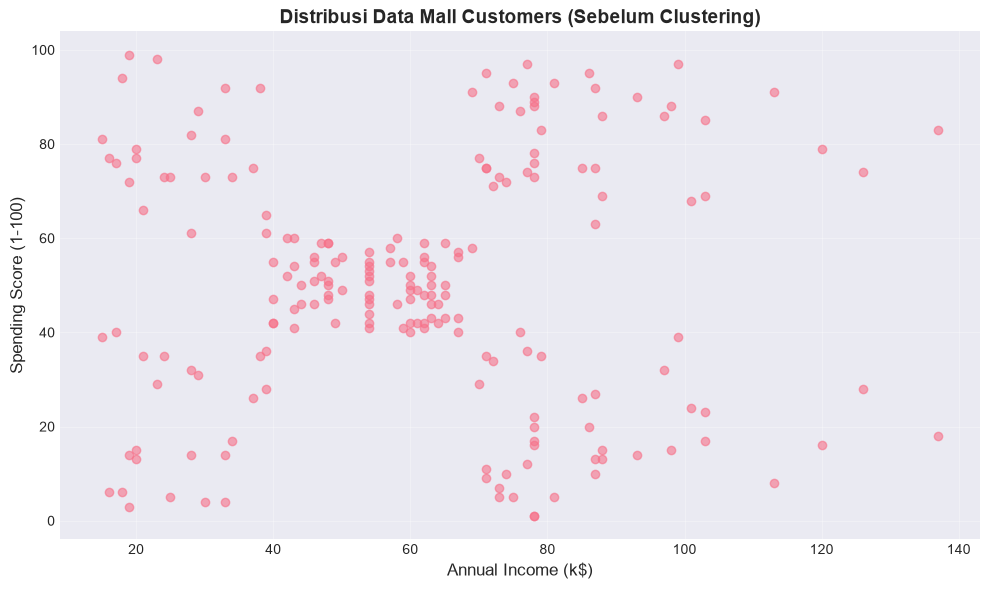

In [7]:
# Visualisasi data sebelum clustering
plt.figure(figsize=(10, 6))
plt.scatter(X_kmeans[:, 0], X_kmeans[:, 1], alpha=0.6)
plt.xlabel('Annual Income (k$)', fontsize=12)
plt.ylabel('Spending Score (1-100)', fontsize=12)
plt.title('Distribusi Data Mall Customers (Sebelum Clustering)', fontsize=14, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

---
## SOAL 3: Buatlah model K-Means dengan mempertimbangkan jumlah k yang terbaik
---

d:\Aplikasi\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
d:\Aplikasi\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
d:\Aplikasi\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


K=2: Inertia = 181363.60
K=3: Inertia = 106348.37
K=4: Inertia = 73679.79


d:\Aplikasi\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
d:\Aplikasi\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
d:\Aplikasi\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


K=5: Inertia = 44448.46
K=6: Inertia = 37233.81
K=7: Inertia = 30241.34


d:\Aplikasi\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
d:\Aplikasi\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
d:\Aplikasi\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


K=8: Inertia = 25036.42
K=9: Inertia = 21916.79
K=10: Inertia = 20072.07


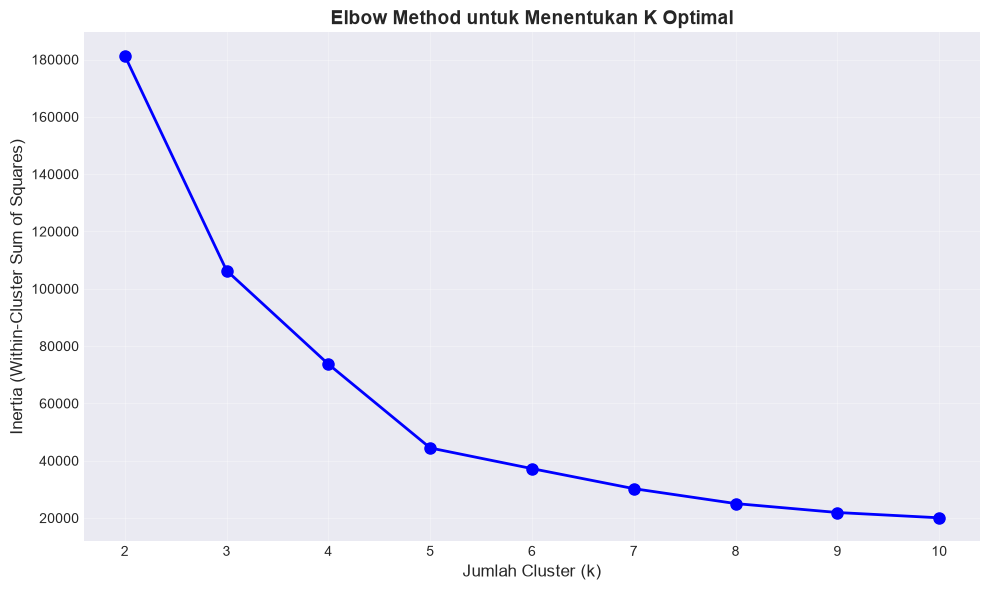


Berdasarkan Elbow Curve di atas, k=5 adalah pilihan yang baik.


In [8]:
# Menggunakan Elbow Method untuk menentukan k terbaik
inertia_values = []
k_range = range(2, 11)

for k in k_range:
    kmeans_temp = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans_temp.fit(X_kmeans)
    inertia_values.append(kmeans_temp.inertia_)
    print(f"K={k}: Inertia = {kmeans_temp.inertia_:.2f}")

# Plot Elbow Curve
plt.figure(figsize=(10, 6))
plt.plot(k_range, inertia_values, 'bo-', linewidth=2, markersize=8)
plt.xlabel('Jumlah Cluster (k)', fontsize=12)
plt.ylabel('Inertia (Within-Cluster Sum of Squares)', fontsize=12)
plt.title('Elbow Method untuk Menentukan K Optimal', fontsize=14, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.xticks(k_range)
plt.tight_layout()
plt.show()

print("\nBerdasarkan Elbow Curve di atas, k=5 adalah pilihan yang baik.")

In [9]:
# Membuat model K-Means dengan k=5

optimal_k = 5
kmeans_model = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
y_kmeans = kmeans_model.fit_predict(X_kmeans)

print(f"\nModel K-Means berhasil dibuat dengan {optimal_k} cluster")
print(f"Inertia: {kmeans_model.inertia_:.2f}")
print(f"\nJumlah data per cluster:")
for i in range(optimal_k):
    print(f"  Cluster {i}: {np.sum(y_kmeans == i)} pelanggan")


Model K-Means berhasil dibuat dengan 5 cluster
Inertia: 44448.46

Jumlah data per cluster:
  Cluster 0: 81 pelanggan
  Cluster 1: 39 pelanggan
  Cluster 2: 22 pelanggan
  Cluster 3: 35 pelanggan
  Cluster 4: 23 pelanggan


d:\Aplikasi\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


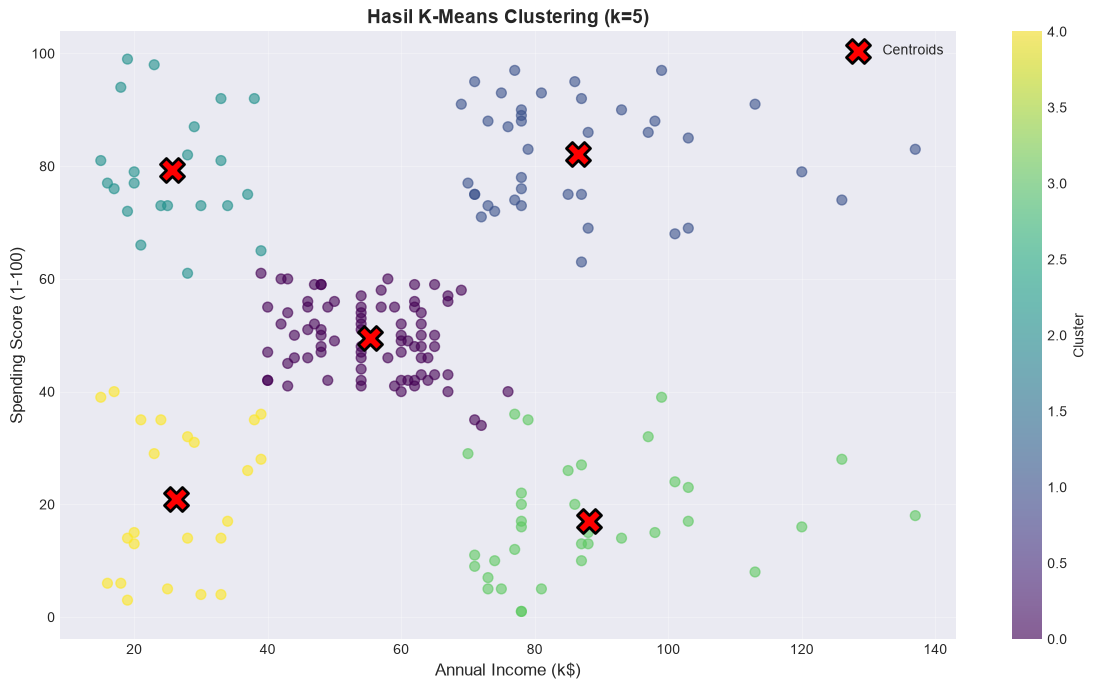

In [11]:
# Visualisasi hasil clustering
plt.figure(figsize=(12, 7))

# Plot data points dengan warna sesuai cluster
scatter = plt.scatter(X_kmeans[:, 0], X_kmeans[:, 1], 
                     c=y_kmeans, cmap='viridis', alpha=0.6, s=50)

# Plot centroid
centers = kmeans_model.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], 
           c='red', marker='X', s=300, edgecolors='black', linewidths=2,
           label='Centroids')

plt.xlabel('Annual Income (k$)', fontsize=12)
plt.ylabel('Spending Score (1-100)', fontsize=12)
plt.title(f'Hasil K-Means Clustering (k={optimal_k})', fontsize=14, fontweight='bold')
plt.colorbar(scatter, label='Cluster')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

---
---
# BAGIAN 2: TUGAS DBSCAN
---
---

---
## SOAL 1: Buat dataset make_moons (1000 sampel, noise=0.05), lalu normalisasi
---

In [12]:
# Generate dataset make_moons
X_moons, y_true = make_moons(n_samples=1000, noise=0.05, random_state=42)

print(f"\nDataset make_moons berhasil dibuat:")
print(f"  - Jumlah sampel: {X_moons.shape[0]}")
print(f"  - Noise: 0.05")
print(f"  - Shape: {X_moons.shape}")

# Normalisasi data
scaler = StandardScaler()
X_moons_scaled = scaler.fit_transform(X_moons)

print(f"\nData berhasil dinormalisasi menggunakan StandardScaler")
print(f"  - Mean sebelum: {X_moons.mean(axis=0)}")
print(f"  - Mean sesudah: {X_moons_scaled.mean(axis=0)}")
print(f"  - Std sebelum: {X_moons.std(axis=0)}")
print(f"  - Std sesudah: {X_moons_scaled.std(axis=0)}")


Dataset make_moons berhasil dibuat:
  - Jumlah sampel: 1000
  - Noise: 0.05
  - Shape: (1000, 2)

Data berhasil dinormalisasi menggunakan StandardScaler
  - Mean sebelum: [0.49925327 0.2486601 ]
  - Mean sesudah: [-2.53075338e-16 -3.20854454e-16]
  - Std sebelum: [0.86775501 0.49603008]
  - Std sesudah: [1. 1.]


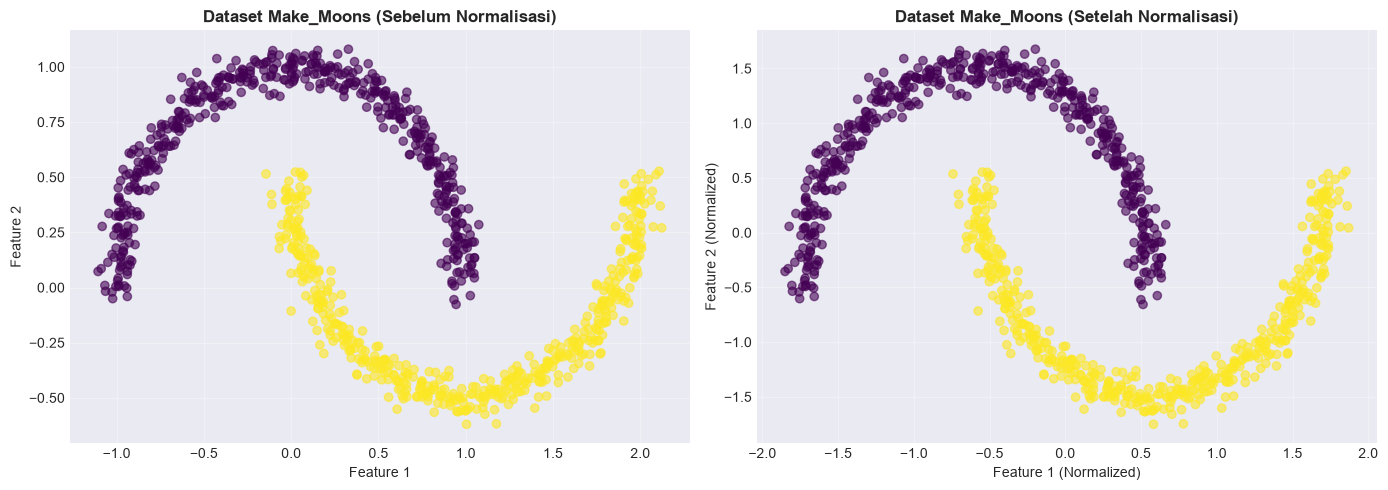

In [13]:
# Visualisasi dataset
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Sebelum normalisasi
axes[0].scatter(X_moons[:, 0], X_moons[:, 1], c=y_true, cmap='viridis', alpha=0.6)
axes[0].set_title('Dataset Make_Moons (Sebelum Normalisasi)', fontweight='bold')
axes[0].set_xlabel('Feature 1')
axes[0].set_ylabel('Feature 2')
axes[0].grid(True, alpha=0.3)

# Sesudah normalisasi
axes[1].scatter(X_moons_scaled[:, 0], X_moons_scaled[:, 1], c=y_true, cmap='viridis', alpha=0.6)
axes[1].set_title('Dataset Make_Moons (Setelah Normalisasi)', fontweight='bold')
axes[1].set_xlabel('Feature 1 (Normalized)')
axes[1].set_ylabel('Feature 2 (Normalized)')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---
## SOAL 2: Jalankan DBSCAN dengan eps=0.2, min_samples=5, hitung jumlah klaster & noise
---

In [14]:
# Jalankan DBSCAN
dbscan_model = DBSCAN(eps=0.2, min_samples=5)
y_dbscan = dbscan_model.fit_predict(X_moons_scaled)

# Hitung jumlah cluster dan noise
n_clusters = len(set(y_dbscan)) - (1 if -1 in y_dbscan else 0)
n_noise = list(y_dbscan).count(-1)

print(f"\nHasil DBSCAN:")
print(f"  - Epsilon (eps): 0.2")
print(f"  - Min samples: 5")
print(f"  - Jumlah cluster: {n_clusters}")
print(f"  - Jumlah noise points: {n_noise}")
print(f"\nDistribusi data per cluster:")
for i in range(-1, n_clusters):
    count = np.sum(y_dbscan == i)
    if i == -1:
        print(f"  Noise: {count} points")
    else:
        print(f"  Cluster {i}: {count} points")


Hasil DBSCAN:
  - Epsilon (eps): 0.2
  - Min samples: 5
  - Jumlah cluster: 2
  - Jumlah noise points: 0

Distribusi data per cluster:
  Noise: 0 points
  Cluster 0: 500 points
  Cluster 1: 500 points


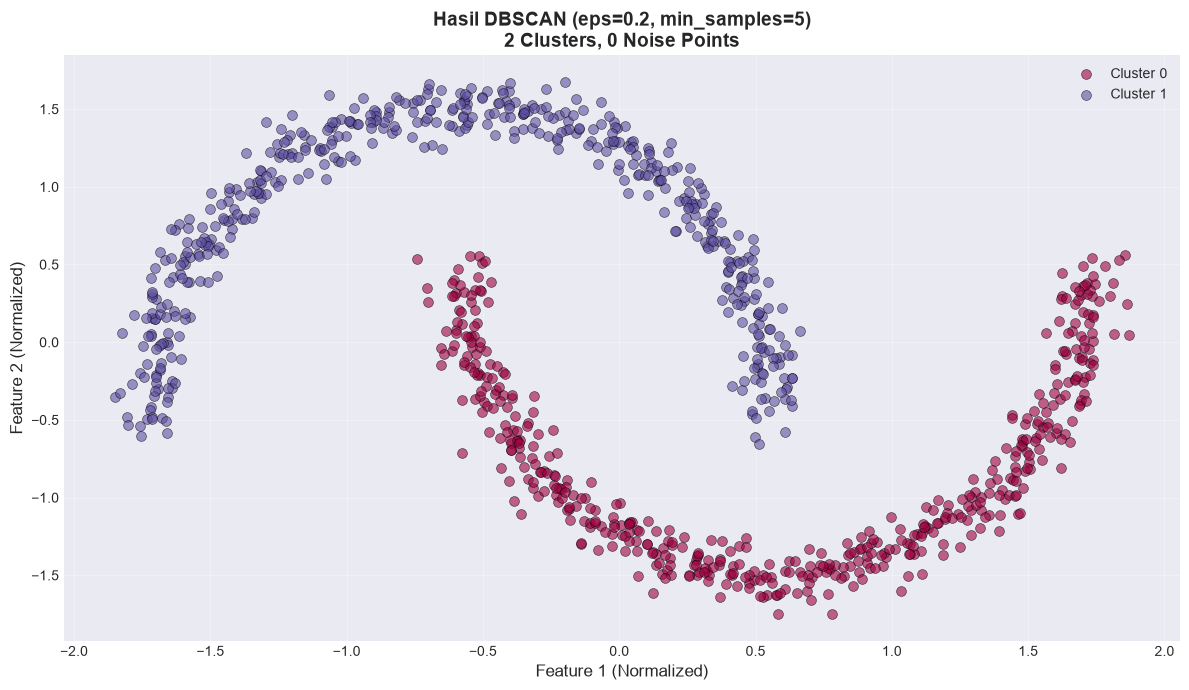

In [15]:
# Visualisasi hasil DBSCAN
plt.figure(figsize=(12, 7))

# Plot dengan warna berbeda untuk setiap cluster dan noise
unique_labels = set(y_dbscan)
colors = plt.cm.Spectral(np.linspace(0, 1, len(unique_labels)))

for k, col in zip(unique_labels, colors):
    if k == -1:
        # Noise points dengan warna hitam
        col = 'black'
        label = 'Noise'
        marker = 'x'
        size = 50
    else:
        label = f'Cluster {k}'
        marker = 'o'
        size = 50
    
    class_member_mask = (y_dbscan == k)
    xy = X_moons_scaled[class_member_mask]
    plt.scatter(xy[:, 0], xy[:, 1], c=[col], marker=marker, s=size, 
               alpha=0.6, label=label, edgecolors='black', linewidths=0.5)

plt.xlabel('Feature 1 (Normalized)', fontsize=12)
plt.ylabel('Feature 2 (Normalized)', fontsize=12)
plt.title(f'Hasil DBSCAN (eps=0.2, min_samples=5)\n{n_clusters} Clusters, {n_noise} Noise Points', 
         fontsize=14, fontweight='bold')
plt.legend(loc='best')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

---
## SOAL 3: Evaluasi dengan metrik: Homogeneity, Completeness, V-measure, ARI, AMI, Silhouette
---

In [16]:
# Hitung semua metrik evaluasi
homogeneity = homogeneity_score(y_true, y_dbscan)
completeness = completeness_score(y_true, y_dbscan)
v_measure = v_measure_score(y_true, y_dbscan)
ari = adjusted_rand_score(y_true, y_dbscan)
ami = adjusted_mutual_info_score(y_true, y_dbscan)
silhouette = silhouette_score(X_moons_scaled, y_dbscan)

print(f"\nMetrik Evaluasi DBSCAN:")
print(f"  1. Homogeneity Score    : {homogeneity:.4f}")
print(f"  2. Completeness Score   : {completeness:.4f}")
print(f"  3. V-Measure Score      : {v_measure:.4f}")
print(f"  4. Adjusted Rand Index  : {ari:.4f}")
print(f"  5. Adjusted Mutual Info : {ami:.4f}")
print(f"  6. Silhouette Score     : {silhouette:.4f}")

print("\nInterpretasi:")
print("  - Skor mendekati 1.0 menunjukkan kualitas clustering yang baik")
print("  - Skor mendekati 0.0 menunjukkan kualitas clustering yang buruk")


Metrik Evaluasi DBSCAN:
  1. Homogeneity Score    : 1.0000
  2. Completeness Score   : 1.0000
  3. V-Measure Score      : 1.0000
  4. Adjusted Rand Index  : 1.0000
  5. Adjusted Mutual Info : 1.0000
  6. Silhouette Score     : 0.3912

Interpretasi:
  - Skor mendekati 1.0 menunjukkan kualitas clustering yang baik
  - Skor mendekati 0.0 menunjukkan kualitas clustering yang buruk


---
## SOAL 4: Visualisasikan hasil DBSCAN (core sample = titik besar, non-core = titik kecil, noise = hitam)
---


Analisis Sample Points:
  - Core samples: 1000 points
  - Non-core samples: 0 points
  - Noise samples: 0 points


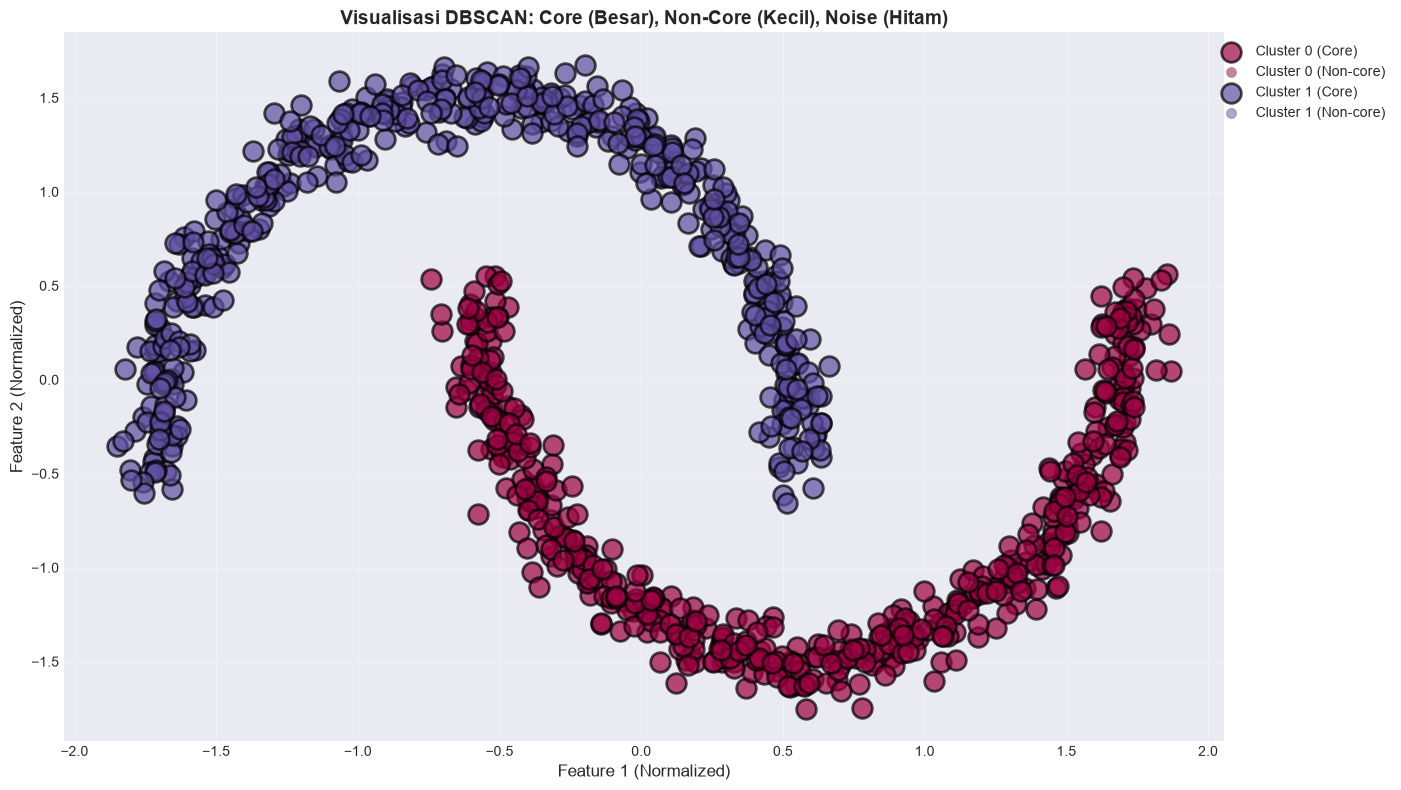

In [17]:
# Identifikasi core samples
core_samples_mask = np.zeros_like(y_dbscan, dtype=bool)
core_samples_mask[dbscan_model.core_sample_indices_] = True

print(f"\nAnalisis Sample Points:")
print(f"  - Core samples: {np.sum(core_samples_mask)} points")
print(f"  - Non-core samples: {np.sum(~core_samples_mask & (y_dbscan != -1))} points")
print(f"  - Noise samples: {np.sum(y_dbscan == -1)} points")

# Visualisasi dengan tiga jenis points
plt.figure(figsize=(14, 8))

unique_labels = set(y_dbscan)
colors = plt.cm.Spectral(np.linspace(0, 1, len(unique_labels)))

for k, col in zip(unique_labels, colors):
    if k == -1:
        # NOISE: titik hitam kecil
        col = 'black'
        class_member_mask = (y_dbscan == k)
        xy = X_moons_scaled[class_member_mask]
        plt.scatter(xy[:, 0], xy[:, 1], c='black', marker='x', s=50, 
                   alpha=0.8, label='Noise', linewidths=2)
    else:
        class_member_mask = (y_dbscan == k)
        
        # CORE SAMPLES: titik besar
        xy_core = X_moons_scaled[class_member_mask & core_samples_mask]
        plt.scatter(xy_core[:, 0], xy_core[:, 1], c=[col], marker='o', s=200, 
                   alpha=0.7, edgecolors='black', linewidths=2,
                   label=f'Cluster {k} (Core)')
        
        # NON-CORE SAMPLES: titik kecil
        xy_noncore = X_moons_scaled[class_member_mask & ~core_samples_mask]
        plt.scatter(xy_noncore[:, 0], xy_noncore[:, 1], c=[col], marker='o', s=50, 
                   alpha=0.5, edgecolors='gray', linewidths=1,
                   label=f'Cluster {k} (Non-core)')

plt.xlabel('Feature 1 (Normalized)', fontsize=12)
plt.ylabel('Feature 2 (Normalized)', fontsize=12)
plt.title('Visualisasi DBSCAN: Core (Besar), Non-Core (Kecil), Noise (Hitam)', 
         fontsize=14, fontweight='bold')
plt.legend(loc='best', bbox_to_anchor=(1.15, 1))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

---
## SOAL 5: Lakukan eksperimen dengan berbagai parameter eps dan min_samples
---

In [18]:
# Parameter untuk eksperimen
eps_values = [0.05, 0.1, 0.3, 0.5]
min_samples_values = [3, 10, 20]

print("\nParameter yang akan diuji:")
print(f"  - Epsilon (eps): {eps_values}")
print(f"  - Min samples: {min_samples_values}")
print(f"  - Total kombinasi: {len(eps_values) * len(min_samples_values)}")

# Simpan hasil eksperimen
results = []

print("\n" + "-"*80)
print(f"{'eps':<8} {'min_samples':<12} {'n_clusters':<12} {'n_noise':<10} {'Silhouette':<12}")
print("-"*80)

for eps in eps_values:
    for min_samples in min_samples_values:
        # Jalankan DBSCAN
        dbscan_exp = DBSCAN(eps=eps, min_samples=min_samples)
        labels = dbscan_exp.fit_predict(X_moons_scaled)
        
        # Hitung metrik
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        n_noise = list(labels).count(-1)
        
        # Silhouette score (hanya jika ada lebih dari 1 cluster)
        if n_clusters > 1:
            sil_score = silhouette_score(X_moons_scaled, labels)
        else:
            sil_score = -1  # Invalid score
        
        results.append({
            'eps': eps,
            'min_samples': min_samples,
            'n_clusters': n_clusters,
            'n_noise': n_noise,
            'silhouette': sil_score
        })
        
        print(f"{eps:<8.2f} {min_samples:<12} {n_clusters:<12} {n_noise:<10} {sil_score:<12.4f}")

print("-"*80)


Parameter yang akan diuji:
  - Epsilon (eps): [0.05, 0.1, 0.3, 0.5]
  - Min samples: [3, 10, 20]
  - Total kombinasi: 12

--------------------------------------------------------------------------------
eps      min_samples  n_clusters   n_noise    Silhouette  
--------------------------------------------------------------------------------
0.05     3            69           186        0.1129      
0.05     10           3            970        -0.2942     
0.05     20           0            1000       -1.0000     
0.10     3            2            14         0.2517      
0.10     10           7            57         0.1623      
0.10     20           6            850        -0.3602     
0.30     3            2            0          0.3912      
0.30     10           2            0          0.3912      
0.30     20           2            0          0.3912      
0.50     3            2            0          0.3912      
0.50     10           2            0          0.3912      
0.50   

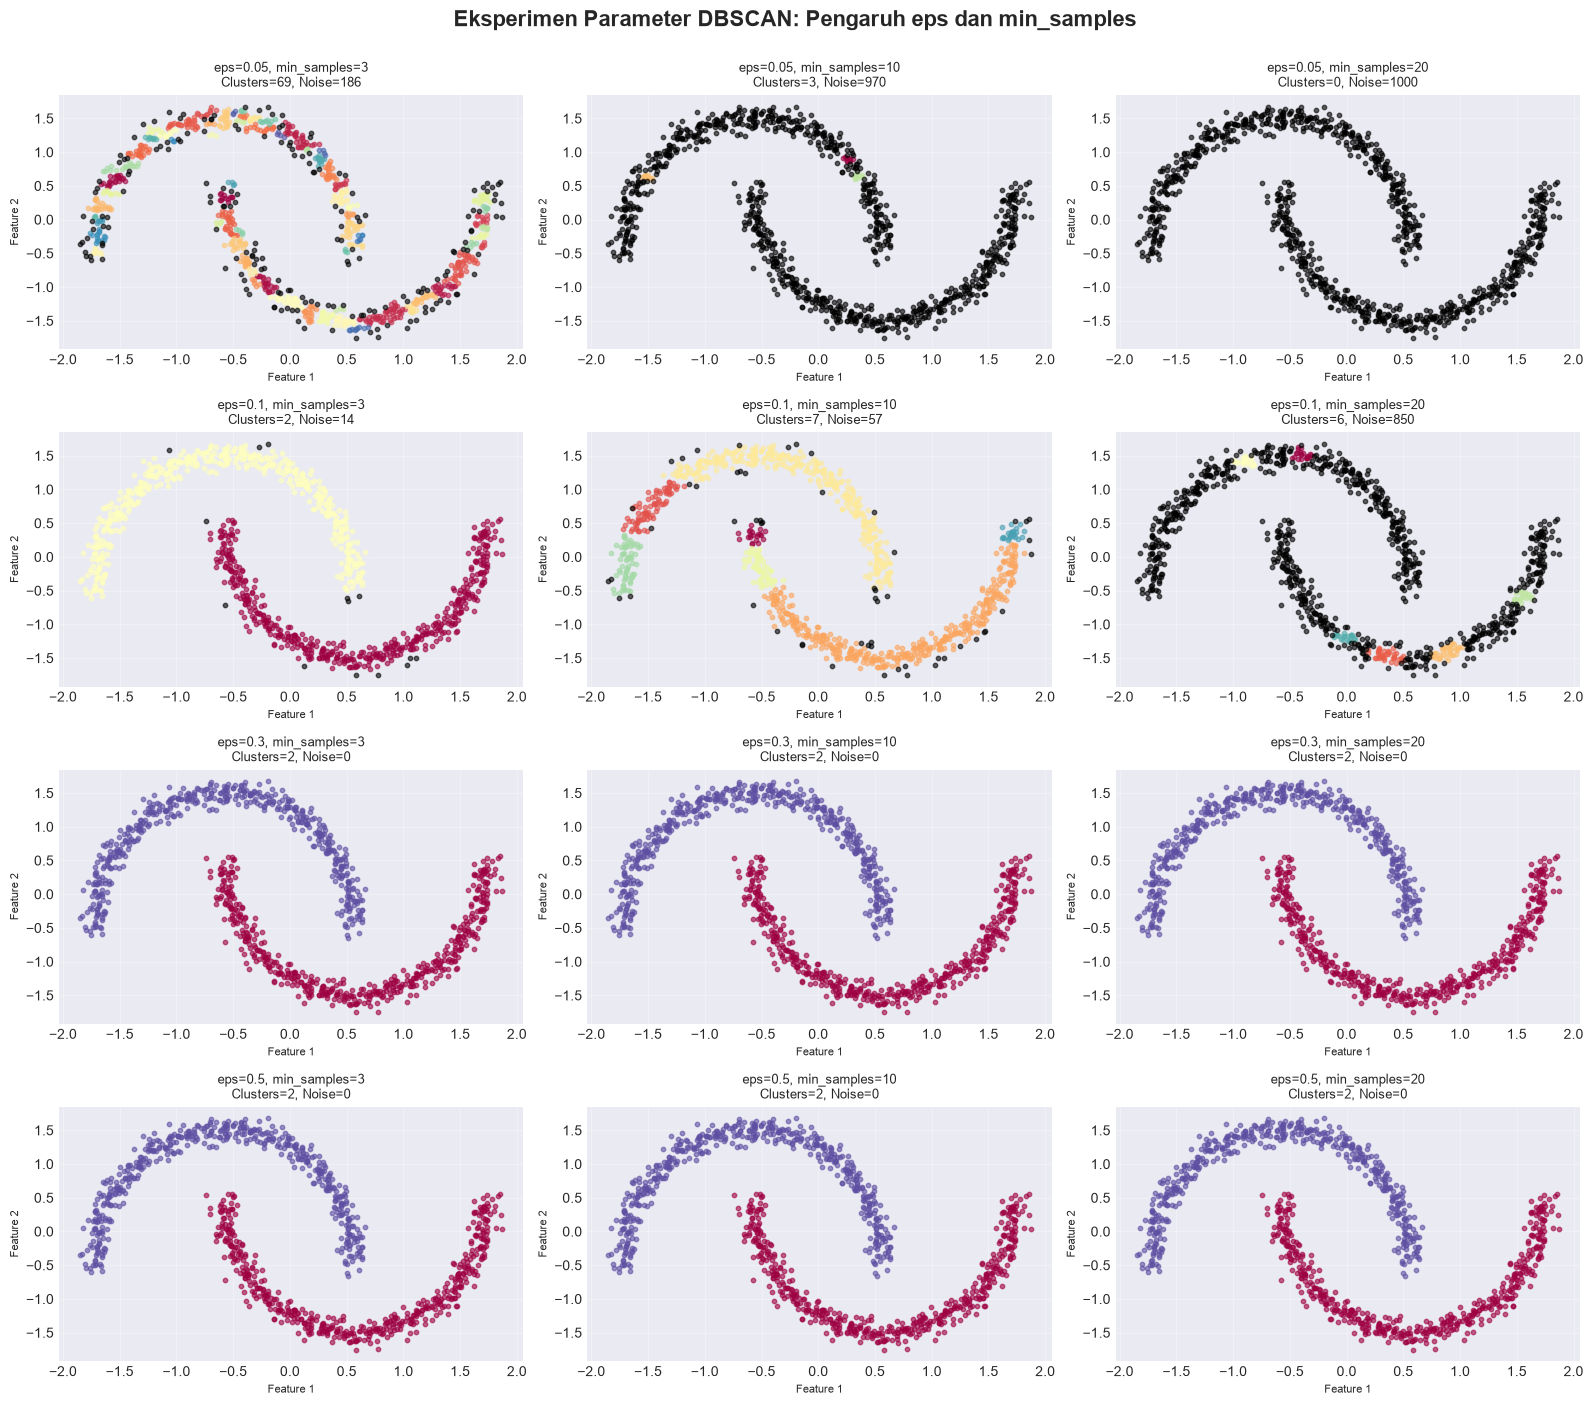

In [19]:
# Visualisasi grid hasil eksperimen
fig, axes = plt.subplots(len(eps_values), len(min_samples_values), 
                         figsize=(16, 14))

idx = 0
for i, eps in enumerate(eps_values):
    for j, min_samples in enumerate(min_samples_values):
        # Ambil hasil eksperimen
        result = results[idx]
        
        # Jalankan DBSCAN lagi untuk visualisasi
        dbscan_viz = DBSCAN(eps=eps, min_samples=min_samples)
        labels_viz = dbscan_viz.fit_predict(X_moons_scaled)
        
        # Plot
        ax = axes[i, j]
        unique_labels = set(labels_viz)
        colors = plt.cm.Spectral(np.linspace(0, 1, len(unique_labels)))
        
        for k, col in zip(unique_labels, colors):
            if k == -1:
                col = 'black'
            class_member_mask = (labels_viz == k)
            xy = X_moons_scaled[class_member_mask]
            ax.scatter(xy[:, 0], xy[:, 1], c=[col], marker='o', s=10, alpha=0.6)
        
        ax.set_title(f"eps={eps}, min_samples={min_samples}\n"
                    f"Clusters={result['n_clusters']}, Noise={result['n_noise']}",
                    fontsize=9)
        ax.grid(True, alpha=0.3)
        ax.set_xlabel('Feature 1', fontsize=8)
        ax.set_ylabel('Feature 2', fontsize=8)
        
        idx += 1

plt.suptitle('Eksperimen Parameter DBSCAN: Pengaruh eps dan min_samples', 
            fontsize=16, fontweight='bold', y=1.00)
plt.tight_layout()
plt.show()

---
---
# KESIMPULAN
---
---

### K-Means:
- Dataset Mall_Customers berhasil di-cluster menjadi 5 kelompok berdasarkan Annual Income dan Spending Score
- Metode Elbow digunakan untuk menentukan jumlah cluster optimal
- Hasil clustering dapat digunakan untuk segmentasi pelanggan dalam bisnis retail

### DBSCAN:
- Dataset make_moons berhasil di-cluster menggunakan DBSCAN dengan kemampuan mendeteksi noise
- Parameter eps dan min_samples sangat mempengaruhi hasil clustering
- DBSCAN cocok untuk data dengan bentuk non-spherical (seperti bulan)
- Metrik evaluasi menunjukkan kualitas clustering yang baik